# AM115 Mini-Project Final Deliverable - How Well Calibrated Are Prediction Markets?

**Date:** October 16, 2026

**Group:** Jacob Lin, Mustapha Sadiq, and Hanser Yoon

**Summary**: We study whether Polymarket prices are reliable probability forecasts. For example, among contracts priced at 70%, we would expect about 70% to resolve in favor of the quoted outcome. We compare prices with actual outcomes using 16,573 contracts with recorded price observations, examining opening prices and prices at several later horizons.
The market probabilities contain useful information, but they do not perfectly match observed outcome frequencies. We therefore fit a simple adjustment using earlier markets and test it on later markets. The adjustment produces small improvements in prediction accuracy at opening and at the 30-day and 7-day horizons. At the 1-day horizon, the evidence does not clearly establish an improvement. These findings apply to the contracts with usable prices in our dataset; because different contracts are available at different horizons, they do not establish that forecasts consistently improve as an event approaches.

**Data:** `full_markets.parquet` (69 MB, included in this upload) holds one row per resolved binary market. It was produced by `extract_full.py` (included) from the raw Polymarket Full Market Dataset snapshot of 2026-04-29 on Hugging Face, [od2961/polymarket-full-market-dataset](https://huggingface.co/datasets/od2961/polymarket-full-market-dataset). The raw JSON (about 7 GB) is too large to include. To rebuild the parquet, download the 2026-04-29 snapshot JSON from that page and run `python extract_full.py <snapshot>.json full_markets.parquet` (10-30 minutes; needs `ijson`, listed in `requirements.txt`).

**Reproducing results:** keep `full_markets.parquet` next to this notebook, `pip install -r requirements.txt`, then Kernel → Restart & Run All (about 2 minutes).
Every random draw comes from a NumPy generator passed to functions as an `rng` argument and seeded from `SEED = 20261016`, recorded in the Setup cell, so a rerun reproduces every number below.

## Setup

In [1]:
from pathlib import Path
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, multivariate_normal
from scipy.special import expit
from sklearn.metrics import roc_auc_score
from sklearn.isotonic import IsotonicRegression

SEED = 20261016                     # recorded seed: every random draw below comes from rng = default_rng(SEED)
DATA_PATH = Path('full_markets.parquet')   # output of extract_full.py, shipped next to this notebook
SNAPSHOT_END = pd.Timestamp('2026-04-30', tz='UTC')   # end of the 2026-04-29 snapshot day
SPLIT_DATE = '2026-01-01'           # validation split, placed using resolution-date counts only (about 70% fit / 30% held out)
STALE_MAX_DAYS = 3                  # full data: a horizon price counts only if the last real trade is within this many days
EDGES = np.linspace(0, 1, 11)       # ten equal-width price bins
pd.set_option('display.width', 160)
print('seed', SEED)

seed 20261016


### Data: loading, categories, clusters

In [2]:
CATS = [  # keyword rules, first match wins; crude by design, spot-checked by hand
 ('social media counts', r'\btweet|\bpost \d|posts? .*times|# of|number of .*(post|tweet)|elon musk post'),
 ('crypto', r'\b(bitcoin|btc|ethereum|eth|solana|sol|xrp|dogecoin|crypto)\b'),
 ('sports', r'\bvs\.?\b| o/u |spread|\b(nba|nfl|mlb|nhl|ufc|fifa|epl|premier league|champions league|la liga|serie a|bundesliga|grand slam|atp|wta|f1|grand prix|super bowl|world series|stanley cup|playoffs?|odi|t20|test match|lol|cs2|dota|valorant|esports|map \d|game \d)\b|points|rebounds|assists|goals scored|win the (series|match|game|title|championship|cup)'),
 ('elections & polls', r'\b(election|elected|primary|nominee|nomination|electoral|vote share|popular vote|approval rating|polls?|senate race|governor|mayor|closest state|win .* (seat|district|state))\b'),
 ('geopolitics & military', r'\b(strike|strikes|ceasefire|invade|invasion|troops|forces|military|missile|drone|war\b|attack|iran|israel|gaza|lebanon|hezbollah|hamas|houthi|ukraine|russia|putin|zelensky|nato|nuclear|venezuela|maduro|china .* taiwan)\b'),
 ('economics & policy', r'\b(fed|fomc|interest rates?|rate (cut|hike)|cpi|inflation|gdp|unemployment|jobs report|recession|tariff|shutdown|debt ceiling|executive order|bill|signed into law|supreme court|court|ruling|indict|sentenc|pardon|trump (say|sign)|doge)\b'),
 ('tech & companies', r'\b(openai|gpt|chatgpt|claude|anthropic|gemini|google|apple|iphone|tesla|nvidia|microsoft|meta|amazon|spacex|starship|ipo|earnings|market cap|stock|release[sd]?|launch|model)\b'),
 ('culture & entertainment', r'\b(oscar|grammy|emmy|album|song|movie|box office|netflix|spotify|billboard|taylor swift|kendrick|drake|time person of the year|most searched|youtube|mrbeast)\b'),
 ('weather & science', r'\b(temperature|weather|hurricane|rain|snow|earthquake|heat|hottest)\b'),
]

def categorise(question):
    s = question.lower()
    return next((name for name, pat in CATS if re.search(pat, s)), 'other')

def template(question):
    """Mask numbers, ranges, months and weekdays, so brackets of one event and days of one series share a template."""
    s = question.lower()
    s = re.sub(r'\$?\d[\d,\.]*%?', '#', s)
    s = re.sub(r'\b(jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\b', 'MON', s)
    s = re.sub(r'\b(monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b', 'DAY', s)
    s = re.sub(r'#(\s*[-–]\s*#)+', '#', s)
    return re.sub(r'\s+', ' ', s).strip()

COARSE = [  # dataset tag -> coarse category; first match wins; question-keyword rules are the fallback
 ('crypto', r'up or down|crypto|bitcoin|ethereum|solana|xrp|ripple|doge|memecoin|airdrop|\b(btc|eth|ltc|base|based|cmc|coinbase|hit price|15m|5m|1h|4h)\b'),
 ('esports', r'esport|league of legends|\blol\b|counter.?strike|\bcs2\b|dota|call of duty|valorant'),
 ('sports', r'sport|tennis|\bgames?\b|nba|nfl|mlb|nhl|ncaa|cfb|epl|soccer|basketball|football|hockey|golf|pga|ufc|cricket|mls|formula|grand prix|f1|nascar|olympic|chess|rugby|boxing|premier league|la liga|serie a|champions league|europa|eredivisie|cup|playoff|super bowl|march madness|wnba|draft|pickleball|skiing|paralympic|matchday|game props|parlay|penalties|margin'),
 ('weather', r'weather|wildfire|temperature|hurricane|climate'),
 ('social media counts', r'mention|tweet|elon musk|twitter'),
 ('politics & elections', r'politic|election|trump|biden|kamala|vance|poll|pardon|executive|bill\b|congress|senate|mayor|cabinet|inaugurat|debate|approval|maga|rfk|gabbard|patel|mamdani|adams|current-affairs|presidency|abortion|trial'),
 ('geopolitics', r'geopolit|world|israel|iran|middle east|ukraine|russia|putin|zelensky|war\b|lebanon|yemen|north korea|india-pakistan|sudan|venezuela|khamenei|netanyahu|nato|defense|army|trade war'),
 ('economy & finance', r'econom|financ|equit|macro|earning|\bfed\b|inflation|unemploy|stock|indic|treasur|comex|nymex|rates|derivativ|banking|\b(amzn|googl|tsla|msft|nvda|pltr|aapl|nflx|abnb|rklb|dji|spx|ndx|rut|nik|dax|ftse|hsi|nya)\b|pre-market|margin'),
 ('tech', r'\btech|\bai\b|openai|gpt|gemini|deepseek|spacex|tiktok|app store|apple|meta\b|google|internet|creators|youtube'),
 ('culture', r'culture|movie|music|award|globe|grammy|oscar|reality|netflix|mrbeast|swift|magazine|film|\brap\b|celebrit|diddy|didy|jake paul|tate|hotdog|queer|new pope|stream'),
]

def coarse_category(tag, question):
    t = str(tag).lower() if tag is not None else ''
    for name, pat in COARSE:
        if re.search(pat, t): return name
    k = categorise(question)                      # fallback: keyword rules on the question text
    return {'elections & polls': 'politics & elections', 'economics & policy': 'economy & finance', 'tech & companies': 'tech',
            'culture & entertainment': 'culture', 'geopolitics & military': 'geopolitics', 'weather & science': 'weather'}.get(k, k)

def find_data(path):
    """Return the path of the extracted parquet, next to the notebook or under data/.  It is produced by
    extract_full.py from the raw Hugging Face snapshot (see the summary for the link)."""
    for p in (path, Path('data') / path.name):
        if p.exists(): return p
    raise FileNotFoundError(f'{path} not found. Put full_markets.parquet next to this notebook, or rebuild it with '
                            f'python extract_full.py <snapshot>.json full_markets.parquet')

def load_markets(path):
    """One row per resolved binary market from the output of extract_full.py: question, y, t_resolve, category,
    event (the dataset's event id), series (series id, else the question template), and one q_* column per horizon.
    Horizon prices are anchored to the EVENT (earlier of market end and resolution); stale prices are dropped."""
    f = pd.read_parquet(path)
    not_final = f.uma_status.isin(['proposed', 'requested', 'disputed'])         # resolution not final: exclude
    print(f'excluding {int(not_final.sum())} markets whose resolution is not final (status proposed/requested/disputed); '
          f'outcomes for {(f.resolution_method == "price_extreme").mean():.1%} of markets are inferred from the terminal price')
    f = f[~not_final]
    ev = f.event_id.astype('Int64').astype(str)
    d = pd.DataFrame({'question': f.question, 'y': f.y.astype(int), 'volume': f.volume, 't_open': f.t_open,
                      't_resolve': f.t_resolution, 'has_real_candles': f.has_real_candles,
                      'category': [coarse_category(c, q) for c, q in zip(f.category, f.question)],
                      'event': ev, 'series': f.series_id.astype('Int64').astype(str).where(f.series_id.notna(), f.question.map(template)),
                      'q_open': f.q_open, 'template': f.question.map(template)})
    for h in (30, 7, 1):
        d[f'q_{h}d'] = f[f'q_{h}d_event'].where(f[f'stale_{h}d_event'] <= STALE_MAX_DAYS)
    return d

HORIZON_NAMES = {'q_open': 'at market open', 'q_30d': '30 days before the event',
                 'q_7d': '7 days before the event', 'q_1d': '1 day before the event'}

def bracket_sums(d, price_col, min_size=5):
    """Sum of prices within each event with at least min_size markets; near 1 only if those markets are mutually exclusive."""
    g = d.groupby('event')[price_col].agg(['size', 'sum'])
    return g[g['size'] >= min_size]['sum']

### Model and statistics

In [3]:
def logit(p, eps=1e-3):
    p = np.clip(p, eps, 1 - eps); return np.log(p / (1 - p))

def sigmoid(x):
    return expit(x)          # numerically stable 1 / (1 + exp(-x))

def calib_fit(q, y):
    """Maximum likelihood for P(Y=1 | q) = sigmoid(a + b logit q) by Newton's method.
    Returns ([a, b], inverse Fisher information).  a = 0, b = 1 is perfect calibration."""
    X = np.c_[np.ones_like(q), logit(q)]; w = np.zeros(2)
    for _ in range(100):
        mu = sigmoid(X @ w); H = X.T @ ((mu * (1 - mu))[:, None] * X) + 1e-9 * np.eye(2)
        step = np.linalg.solve(H, X.T @ (y - mu)); w += step
        if np.abs(step).max() < 1e-10: break
    mu = sigmoid(X @ w)
    return w, np.linalg.inv(X.T @ ((mu * (1 - mu))[:, None] * X) + 1e-9 * np.eye(2))

def recalibrate(q, ab):
    return sigmoid(ab[0] + ab[1] * logit(q))

def bin_index(q, edges=EDGES):
    return np.clip(np.digitize(q, edges) - 1, 0, len(edges) - 2)

def reliability_table(q, y, edges=EDGES):
    b = bin_index(q, edges); ks = np.unique(b)
    tab = pd.DataFrame({'bin': ks, 'n': [(b == k).sum() for k in ks],
                        'mean_price': [q[b == k].mean() for k in ks], 'observed': [y[b == k].mean() for k in ks]})
    return tab, b

def ece(q, y, b):
    """Count-weighted mean |observed frequency - mean price| over bins."""
    return sum((b == k).sum() * abs(y[b == k].mean() - q[b == k].mean()) for k in np.unique(b)) / len(q)

def brier_parts(q, y, b):
    """Murphy decomposition over bins: Brier = reliability - resolution + uncertainty
    (exact when prices are constant within bins)."""
    ybar = y.mean(); rel = res = 0.0
    for k in np.unique(b):
        m = b == k; rel += m.sum() * (q[m].mean() - y[m].mean()) ** 2; res += m.sum() * (y[m].mean() - ybar) ** 2
    return dict(brier=np.mean((q - y) ** 2), reliability=rel / len(q), resolution=res / len(q), uncertainty=ybar * (1 - ybar))

def log_loss(p, y, eps=1e-6):
    p = np.clip(p, eps, 1 - eps); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

### Uncertainty

In [4]:
def cluster_boot(df, cluster, stat, rng, n_boot=1000):
    """Resample whole clusters with replacement; each drawn cluster gets a fresh id in column '_bc'."""
    inv = np.unique(df[cluster].to_numpy(), return_inverse=True)[1]
    members = [np.flatnonzero(inv == i) for i in range(inv.max() + 1)]
    out = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(members), len(members))
        sub = df.iloc[np.concatenate([members[i] for i in pick])].copy()
        sub['_bc'] = np.repeat(np.arange(len(pick)), [len(members[i]) for i in pick])
        out.append(stat(sub))
    return np.array(out, dtype=float)

def ci(x, level=0.95):
    return np.nanquantile(x, [(1 - level) / 2, 1 - (1 - level) / 2], axis=0)

def simulate_outcomes(q, rng, n_sim, cluster_ids=None, rho=0.0):
    """Outcomes under PERFECT calibration: P(Y_i = 1) = q_i exactly.  With rho > 0, markets in one cluster
    share a Gaussian factor: Z_i = sqrt(rho) S_c + sqrt(1 - rho) e_i,  Y_i = 1{Z_i < Phi^-1(q_i)}."""
    if rho == 0 or cluster_ids is None:
        return rng.random((n_sim, len(q))) < q
    inv = np.unique(cluster_ids, return_inverse=True)[1]
    Z = np.sqrt(rho) * rng.standard_normal((n_sim, inv.max() + 1))[:, inv] + np.sqrt(1 - rho) * rng.standard_normal((n_sim, len(q)))
    return Z < norm.ppf(np.clip(q, 1e-9, 1 - 1e-9))

def outcome_correlation(q, y, cluster_ids):
    """Pooled within-cluster correlation of residuals r = y - q, over pairs i != j in the same cluster."""
    g = pd.DataFrame({'c': cluster_ids, 'r': y - q, 's': np.sqrt(q * (1 - q))})
    g = g.assign(r2=g.r ** 2, s2=g.s ** 2).groupby('c').sum()
    return (g.r ** 2 - g.r2).sum() / (g.s ** 2 - g.s2).sum()

### Plotting

In [5]:
def reliability_plot(ax, tab, title, curve=None):
    ax.plot([0, 1], [0, 1], ls='--', color='0.6', lw=1, label='perfect calibration')
    if 'null_lo' in tab:
        ax.fill_between(tab.mean_price, tab.null_lo, tab.null_hi, color='0.85', label='95% range if perfectly calibrated')
    ax.errorbar(tab.mean_price, tab.observed, yerr=[tab.observed - tab.lo, tab.hi - tab.observed], fmt='o',
                color='#1f4e79', capsize=3, ms=5, label='observed, 95% CI (event clusters)')
    if curve is not None:
        x = np.linspace(0.005, 0.995, 200); ax.plot(x, curve(x), color='#c0504d', lw=1.5, label='fitted calibration curve')
    for _, r in tab.iterrows():
        ax.annotate(int(r.n), (r.mean_price, r.observed), textcoords='offset points', xytext=(6, -11), fontsize=7, color='0.4')
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='market price (implied probability)', ylabel='fraction resolved YES', title=title)
    ax.set_aspect('equal')

### Load the data and check orientation

In [6]:
d = load_markets(find_data(DATA_PATH))
HORIZONS = {c: HORIZON_NAMES[c] for c in HORIZON_NAMES if c in d}
qcols = list(HORIZONS)
if 'has_real_candles' in d:                                  # full data: how much of it has prices, and is that selective?
    cov = d.groupby('category').agg(markets=('y', 'size'), with_prices=('has_real_candles', 'mean')).sort_values('markets', ascending=False)
    p_cov = d.has_real_candles.mean()
    print(f'{len(d)} resolved binary markets; {p_cov:.2%} (binomial SE {np.sqrt(p_cov * (1 - p_cov) / len(d)):.2%}) have at least one real price')
    print('price coverage by category (a selection check):'); print(cov.head(12).round(3).to_string())
    d = d[d.has_real_candles].copy()
p_yes = d.y.mean()
print(f'{len(d)} markets resolved {d.t_resolve.min().date()} to {d.t_resolve.max().date()}; '
      f'YES rate {p_yes:.3f} (binomial SE {np.sqrt(p_yes * (1 - p_yes) / len(d)):.3f})')
print(f'{int(d.t_resolve.isna().sum())} have no resolution date; {int((d.t_resolve >= SNAPSHOT_END).sum())} carry a resolution date '
      f'after the 2026-04-29 snapshot (scheduled deadlines, kept)')
aucs = {c: roc_auc_score(d.y[d[c].notna()], d[c].dropna()) for c in qcols}
auc_rng = np.random.default_rng(SEED + 1)    # its own stream, so the draws in Sections 4-6 do not depend on this check
auc_ci = {c: ci(cluster_boot(d.dropna(subset=[c])[[c, 'y', 'series']], 'series', lambda s, c=c: roc_auc_score(s.y, s[c]), auc_rng, 200))
          for c in qcols}
print('orientation AUC by horizon, 95% CI from 200 series-bootstrap resamples (below 0.5: recorded price is for the NO side):')
for c in qcols: print(f'   {HORIZONS[c]}: {aucs[c]:.3f}  [{auc_ci[c][0]:.3f}, {auc_ci[c][1]:.3f}]')
print(f'mean bracket-set price sum at open: recorded {bracket_sums(d.dropna(subset=["q_open"]), "q_open").mean():.2f}, '
      f'complement {bracket_sums(d.dropna(subset=["q_open"]).assign(c=lambda t: 1 - t.q_open), "c").mean():.2f}   (near 1 only for mutually exclusive markets)')
flip = np.mean(list(aucs.values())) < 0.5
if flip:
    for c in qcols: d[c] = 1 - d[c]                          # implied P(YES)
print('markets with a usable price per horizon:', {HORIZONS[c]: int(d[c].notna().sum()) for c in qcols})
print('markets by resolution year (for placing SPLIT_DATE by counts alone):', d.t_resolve.dt.year.value_counts().sort_index().to_dict())
composition = d.category.value_counts().to_frame('markets').assign(share=lambda t: t.markets / len(d))
composition['share_se'] = np.sqrt(composition.share * (1 - composition.share) / len(d))   # binomial standard error
composition.round(3)

excluding 227 markets whose resolution is not final (status proposed/requested/disputed); outcomes for 99.1% of markets are inferred from the terminal price


581760 resolved binary markets; 2.85% (binomial SE 0.02%) have at least one real price
price coverage by category (a selection check):
                      markets  with_prices
category                                  
sports                 232073        0.033
crypto                 207982        0.024
esports                 57089        0.016
culture                 19550        0.034
politics & elections    17204        0.037
weather                 13952        0.038
economy & finance       10504        0.042
other                    8568        0.026
tech                     5899        0.037
social media counts      5424        0.046
geopolitics              3515        0.042
16573 markets resolved 2023-03-16 to 2027-01-01; YES rate 0.385 (binomial SE 0.004)
3 have no resolution date; 91 carry a resolution date after the 2026-04-29 snapshot (scheduled deadlines, kept)


orientation AUC by horizon, 95% CI from 200 series-bootstrap resamples (below 0.5: recorded price is for the NO side):
   at market open: 0.695  [0.679, 0.713]
   30 days before the event: 0.941  [0.925, 0.954]
   7 days before the event: 0.851  [0.839, 0.864]
   1 day before the event: 0.839  [0.826, 0.852]
mean bracket-set price sum at open: recorded 3.24, complement 5.28   (near 1 only for mutually exclusive markets)
markets with a usable price per horizon: {'at market open': 16573, '30 days before the event': 1481, '7 days before the event': 4703, '1 day before the event': 10115}
markets by resolution year (for placing SPLIT_DATE by counts alone): {2023.0: 12, 2024.0: 799, 2025.0: 10815, 2026.0: 4928, 2027.0: 16}


,markets,share,share_se
category,,,
sports,7566,0.457,0.004
crypto,4955,0.299,0.004
esports,917,0.055,0.002
culture,671,0.040,0.002
politics & elections,641,0.039,0.001
weather,534,0.032,0.001
economy & finance,444,0.027,0.001
social media counts,249,0.015,0.001
other,226,0.014,0.001


**Reading these checks.** Only 2.85% (SE 0.02%) of the 581,760 resolved binary markets have a real price, and coverage ranges from 1.6% (esports) to 4.6% (social media counts), so the retained sample is a selected one (Section 8). The orientation AUCs are well above 0.5 at every horizon and every 95% interval excludes 0.5, so recorded prices are YES-side and no flip is applied. The bracket-set sums are far from 1 under either orientation (3.24 recorded, 5.28 complement): the dataset's events evidently group markets that are not mutually exclusive, such as several lines or props on one game, so this check cannot decide orientation and we rely on the AUCs. Three retained markets have no resolution date and 91 carry a resolution date after the snapshot; Section 2 states how the validation split treats them. By resolution year, a split at 2026-01-01 puts about 70% of markets in the fitting set and 30% in the held-out set.

## 1. Question
How far does the calibration slope $b$ differ from 1 across Polymarket categories and forecast times?

A market price represents a probability. If contracts priced at 70% win 70% of the time, that price is calibrated. We compare prices with outcome frequencies at opening and at 30, 7, and 1 day before the event anchor.

Our model is a logistic calibration curve, fitted for each category and forecast time. The fit produces the slope $b$. A slope below 1 indicates that probabilities are too extreme; a slope above 1 indicates that they need to move farther toward zero or one, after accounting for the curve’s intercept. Perfect calibration requires both a slope of 1 and an intercept of 0.

We choose this model because it summarizes calibration with two parameters and keeps predicted probabilities between zero and one. We compare it with an isotonic curve to test whether a more flexible shape improves predictions.

We also calculate the resolution term of the Brier score. It measures whether groups of contracts have different outcome frequencies, showing whether the forecasts distinguish events that happen from events that do not. The price histograms show sharpness: how concentrated forecasts are near zero and one.

Here the event anchor is an administrative date: the earlier of recorded market end and recorded resolution. The opening-price field is the opening observation supplied by the extractor, not necessarily a trade at the instant the market was listed.

## 2. Assumptions

| Assumption | Type | Where it breaks |
|---|---|---|
| A logistic curve can describe the relationship between prices and outcome frequencies. | Chosen on purpose | The relationship may have bends that two parameters cannot describe. Section 6 compares the logistic curve with an isotonic curve, which allows more shapes. |
| Ten equal-width price bins provide a useful summary of calibration. | Chosen on purpose | A bin can hide differences between prices or contain too few observations. Section 4.1 compares equal-width bins with equal-count bins. |
| Series capture the dependence between markets needed for uncertainty estimates. | Chosen on purpose | Markets in different series can respond to the same news. Resampling series does not capture dependence across those series. |
| Each price and outcome label refer to the same outcome. | Implicit in pairing prices with `y` | Token order or labels can differ between markets. Pairing one outcome’s price with another outcome’s result changes the calibration estimates. |
| A price selected for a forecast time was available before the answer became known. | Implicit in the horizon data | Public information can reveal the answer before market end or resolution. A price before the administrative timestamp may therefore contain the answer. |
| Markets with usable prices represent the population we discuss. | Implicit in excluding missing prices | Price coverage can differ by category, age, or market duration. Results from retained markets may not apply to excluded markets. |
| Each contract should receive equal weight. | Implicit in the averages and fitted curve | An event with many contracts has more influence than an event with one contract. Results describe a typical retained contract rather than a typical event. |

The tables below describe the input and the retained sample. Counts and shares of the included finite file are descriptive, rather than estimates of all Polymarket contracts. Extreme prices do not establish leakage; a price rounding to 0.50 does not establish that it was a placeholder. The shared-series assumption applies to question-template clusters here, because the input has no usable series IDs among price-covered records.

The date split assumes recorded resolution dates can order fitting outcomes. Markets with no resolution date fall in neither the fitting nor the held-out set. Markets whose recorded resolution date lies after the 2026-04-29 snapshot are kept; those dates are scheduled deadlines rather than observed resolutions, and they fall in the held-out set. A held-out market's price can be dated before the split (an opening price, for example), so this is a retrospective check of transfer across resolution periods, not a strict prospective test.

In [7]:
assumption_checks = pd.Series({
    'price possibly after the answer was known? share of shortest-horizon prices <= 2% or >= 98%': ((d[qcols[-1]] <= .02) | (d[qcols[-1]] >= .98)).mean(),
    'logit clipping at 0.001: share of shortest-horizon prices beyond it': ((d[qcols[-1]] < 1e-3) | (d[qcols[-1]] > 1 - 1e-3)).mean(),
    'seed prices: share of opening prices exactly 0.50': (d.q_open.round(3) == 0.5).mean(),
    'keyword rules failed: share in category "other"': (d.category == 'other').mean(),
    'largest single series as a share of all markets': d.series.value_counts().iloc[0] / len(d),
    'share of markets that share an event cluster with another market': (d.groupby('event').y.transform('size') >= 2).mean(),
}).to_frame('value')
assumption_checks['se'] = np.sqrt(assumption_checks.value * (1 - assumption_checks.value) / len(d))   # binomial SE of a share
assumption_checks.round(3)

,value,se
price possibly after the answer was known? share of shortest-horizon prices <= 2% or >= 98%,0.129,0.003
logit clipping at 0.001: share of shortest-horizon prices beyond it,0.031,0.001
seed prices: share of opening prices exactly 0.50,0.366,0.004
"keyword rules failed: share in category ""other""",0.014,0.001
largest single series as a share of all markets,0.015,0.001
share of markets that share an event cluster with another market,0.624,0.004


## 3. Model
We use the same model for each category and forecast time. Let $N$ be the number of markets with usable prices, $q_i$ the quoted probability for market $i$, and $Y_i$ its outcome. The label $Y_i$ is 1 if the outcome represented by the price wins and 0 otherwise.

### Calibration curve

We model the outcome probability as

$$
P(Y_i=1\mid q_i)=m_i
=\sigma\left(a+b\operatorname{logit}(\widetilde q_i)\right),
$$

where

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\operatorname{logit}(q)=\log\left(\frac{q}{1-q}\right).
$$

The intercept $a$ shifts the curve. The slope $b$ changes how much probabilities move toward zero or one, after accounting for the intercept. We clip prices using

$$
\widetilde q_i=\min(0.999,\max(0.001,q_i))
$$

to keep the logit finite. Perfect calibration corresponds to $a=0$ and $b=1$, apart from clipping at the endpoints.

We estimate $a$ and $b$ by maximizing the Bernoulli log likelihood

$$
\ell(a,b)=
\sum_{i=1}^{N}
\left[
Y_i\log m_i+(1-Y_i)\log(1-m_i)
\right].
$$

The code uses Newton's method to find the estimates.

### Perfect-calibration reference: independent outcomes

Under perfect calibration, a market priced at $q_i$ has probability $q_i$ of winning. We generate

$$
Y_i^{(j)}\sim\operatorname{Bernoulli}(q_i)
$$

independently across markets. Here $j$ identifies a simulation. Prices stay fixed while outcomes change between simulations.

We compare observed bin frequencies and calibration error with their simulated distributions. The gray band shows the interval between the 2.5th and 97.5th percentiles of simulated frequencies in each bin. These are pointwise intervals for each bin.

### Perfect-calibration reference: correlated outcomes

To allow markets in the same series to share information, we generate

$$
Z_i^{(j)}
=
\sqrt{\rho}\,S_{s_i}^{(j)}
+
\sqrt{1-\rho}\,E_i^{(j)},
$$

then set

$$
Y_i^{(j)}
=
\mathbf{1}
\left\{
Z_i^{(j)}<\Phi^{-1}(q_i)
\right\}.
$$

Here:

- $s_i$ identifies market $i$'s series.
- $S_{s_i}^{(j)}$ is a standard normal draw shared by markets in that series.
- $E_i^{(j)}$ is a standard normal draw for market $i$.
- All series factors and market errors are independent.
- $\Phi^{-1}$ is the standard normal quantile function.
- $\mathbf{1}\{\cdot\}$ equals 1 when the condition holds and 0 otherwise.
- $\rho$ controls dependence in the normal variables; it is not the correlation between binary outcomes.

We use $\rho\in\{0,0.05,0.10,0.20,0.30\}$. This construction preserves each market's winning probability while introducing dependence within series. The correlated implementation clips probabilities to $[10^{-9},1-10^{-9}]$ when computing the quantiles.

### Binning and calibration error

We divide prices into ten bins with edges $0,0.1,\ldots,1$. Interior edges belong to the bin on their right; the last bin includes 1.

For each occupied bin $k$, let $n_k$ be its number of markets. Its mean price and outcome frequency are

$$
\bar q_k=\frac{1}{n_k}\sum_{i\in k}q_i,
\qquad
\bar y_k=\frac{1}{n_k}\sum_{i\in k}Y_i.
$$

A reliability plot compares $\bar q_k$ with $\bar y_k$. We summarize their gaps using expected calibration error:

$$
\mathrm{ECE}
=
\sum_k\frac{n_k}{N}
\left|\bar y_k-\bar q_k\right|.
$$

We repeat the calculation with equal-count bins based on price quantiles. Tied prices can reduce the number of distinct bins.

### Brier score and decomposition

The Brier score measures prediction error:

$$
\mathrm{BS}
=
\frac{1}{N}\sum_{i=1}^{N}(q_i-Y_i)^2.
$$

Lower scores indicate less error. Let the overall outcome frequency be

$$
\bar y=\frac{1}{N}\sum_{i=1}^{N}Y_i.
$$

The code calculates three components:

$$
\mathrm{Reliability}
=
\sum_k\frac{n_k}{N}
(\bar q_k-\bar y_k)^2,
$$

$$
\mathrm{Resolution}
=
\sum_k\frac{n_k}{N}
(\bar y_k-\bar y)^2,
$$

$$
\mathrm{Uncertainty}
=
\bar y(1-\bar y).
$$

Reliability measures disagreement between mean prices and outcome frequencies. Resolution measures how much the bin outcome frequencies differ from the overall frequency. Uncertainty measures variation in outcomes before using the forecasts.

When prices are constant within each bin,

$$
\mathrm{BS}
=
\mathrm{Reliability}
-
\mathrm{Resolution}
+
\mathrm{Uncertainty}.
$$

When prices vary within bins, these components give a binned approximation to the raw-price Brier score.

The output labels resolution as “sharpness.” Resolution measures separation in outcome frequencies. Sharpness describes the distribution of forecast probabilities without using outcomes; we show it with the price histograms.

## 4. Estimation and uncertainty

The full-data loader excludes 227 markets with proposed, requested, or disputed resolution status. Of the remaining 581,760 resolved binary markets, 16,573 have at least one real price. The usable counts are 16,573 at opening, 1,481 at 30 days, 4,703 at 7 days, and 10,115 at 1 day. Sports and crypto together account for about three quarters of the retained sample.

The calibration curve is estimated by maximum likelihood. Main 95% intervals come from percentile cluster bootstraps: draw whole series with replacement, retain their markets, and recompute the statistic. This keeps dependence within sampled series while treating series as the resampling units. Fisher standard errors provide an independence-based comparison. Bin-frequency intervals use event clusters instead. The point estimates remain weighted by market.

### 4.1 Calibration and sharpness at four horizons

Intercept, slope, Brier components, and ECE carry 95% intervals from 1,000 series-bootstrap resamples. Bin frequencies use 500 event-bootstrap resamples within each bin. The independent perfect-calibration reference uses 5,000 simulated outcome sets, with the first 2,000 used for ECE tail comparisons.

In [8]:
def fit_horizon(d, qc, rng, n_boot=1000):
    q, y = d[qc].to_numpy(), d.y.to_numpy()
    slim = d[[qc, 'y', 'event', 'series']]
    (a, b), cov = calib_fit(q, y)
    tab, bins = reliability_table(q, y)
    sims = simulate_outcomes(q, rng, 5000)
    tab['null_lo'] = [np.quantile(sims[:, bins == k].mean(1), .025) for k in tab.bin]
    tab['null_hi'] = [np.quantile(sims[:, bins == k].mean(1), .975) for k in tab.bin]
    lohi = [ci(cluster_boot(slim[bins == k], 'event', lambda s: s.y.mean(), rng, 500)) for k in tab.bin]
    tab['lo'], tab['hi'] = [x[0] for x in lohi], [x[1] for x in lohi]
    def stat(s):
        qs, ys = s[qc].to_numpy(), s.y.to_numpy()
        return np.r_[calib_fit(qs, ys)[0], list(brier_parts(qs, ys, bin_index(qs)).values()), ece(qs, ys, bin_index(qs))]
    lo, hi = ci(cluster_boot(slim, 'series', stat, rng, n_boot))
    point = np.r_[a, b, list(brier_parts(q, y, bins).values()), ece(q, y, bins)]
    names = ['intercept a', 'slope b', 'Brier score', 'reliability (calibration error)', 'resolution (sharpness)', 'uncertainty', 'ECE']
    est = pd.DataFrame({'estimate': point, 'ci_lo': lo, 'ci_hi': hi, 'fisher_se': np.r_[np.sqrt(np.diag(cov)), [np.nan] * 5]}, index=names)
    e_null = np.array([ece(q, s.astype(float), bins) for s in sims[:2000]])
    return tab, est, dict(ece_null95=np.quantile(e_null, .95), p=(e_null >= point[-1]).mean())

rng = np.random.default_rng(SEED)
results = {qc: fit_horizon(d.dropna(subset=[qc]), qc, rng) for qc in HORIZONS}
for qc, (tab, est, test) in results.items():
    n_h = d[qc].notna().sum()
    print(f'\n=== {HORIZONS[qc]}: {n_h} markets in {d.dropna(subset=[qc]).series.nunique()} series clusters')
    print(est.round(4).to_string())
    print(f'ECE {est.loc["ECE", "estimate"]:.4f}; 95th percentile under perfect calibration {test["ece_null95"]:.4f}; p = {test["p"]:.4f}')


=== at market open: 16573 markets in 8497 series clusters
                                 estimate   ci_lo   ci_hi  fisher_se
intercept a                       -0.2115 -0.2661 -0.1578     0.0174
slope b                            1.0982  1.0375  1.1672     0.0311
Brier score                        0.2077  0.2015  0.2132        NaN
reliability (calibration error)    0.0034  0.0024  0.0048        NaN
resolution (sharpness)             0.0323  0.0289  0.0365        NaN
uncertainty                        0.2368  0.2321  0.2405        NaN
ECE                                0.0472  0.0376  0.0582        NaN
ECE 0.0472; 95th percentile under perfect calibration 0.0107; p = 0.0000

=== 30 days before the event: 1481 markets in 1327 series clusters
                                 estimate   ci_lo   ci_hi  fisher_se
intercept a                       -0.3123 -0.5079 -0.1320     0.0996
slope b                            1.1111  0.9774  1.2814     0.0755
Brier score                        0.0733

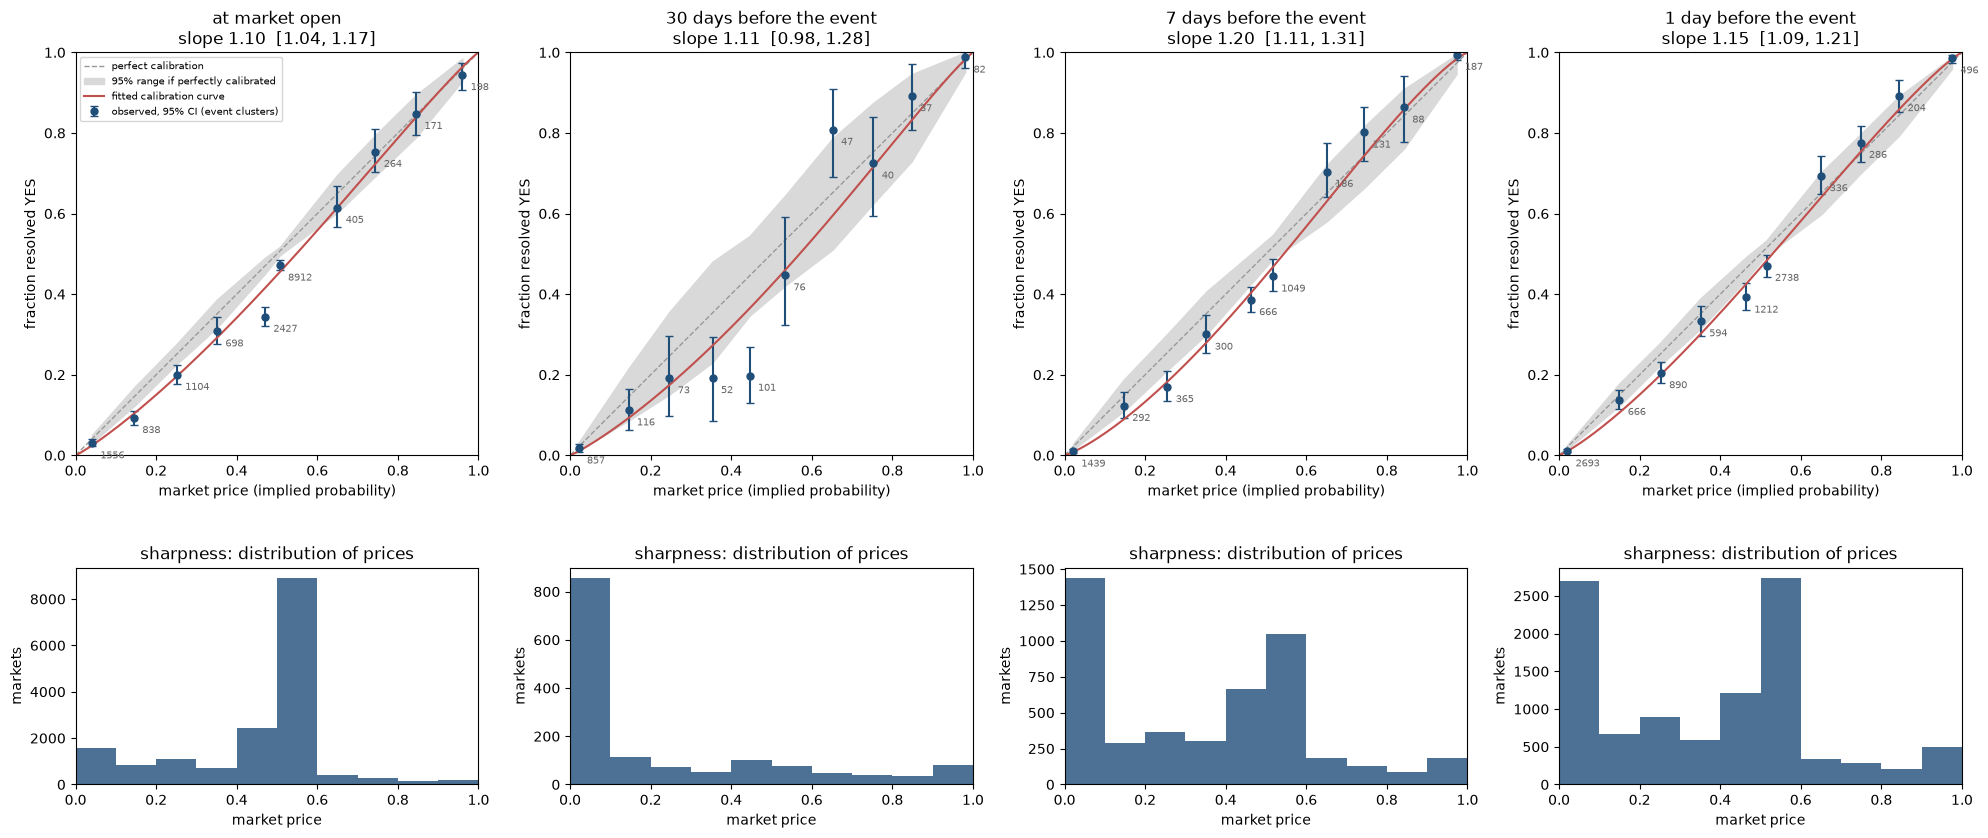

In [9]:
def plot_horizons(d, results):
    fig, axes = plt.subplots(2, len(HORIZONS), figsize=(5 * len(HORIZONS), 9), gridspec_kw=dict(height_ratios=[3, 1.1]), squeeze=False)
    for j, (qc, title) in enumerate(HORIZONS.items()):
        tab, est, _ = results[qc]; ab = est.loc[['intercept a', 'slope b'], 'estimate'].to_numpy(); s = est.loc['slope b']
        reliability_plot(axes[0, j], tab, f'{title}\nslope {s.estimate:.2f}  [{s.ci_lo:.2f}, {s.ci_hi:.2f}]',
                         curve=lambda x, ab=ab: recalibrate(x, ab))
        axes[1, j].hist(d[qc].dropna(), bins=EDGES, color='#1f4e79', alpha=.8)
        axes[1, j].set(xlim=(0, 1), xlabel='market price', ylabel='markets', title='sharpness: distribution of prices')
    axes[0, 0].legend(fontsize=7, loc='upper left'); fig.tight_layout(); plt.show()

plot_horizons(d, results)

At opening, the fitted slope is 1.098 [1.038, 1.167] and the intercept is -0.212 [-0.266, -0.158]. At 7 days, the slope is 1.200 [1.109, 1.310]; at 1 day it is 1.149 [1.092, 1.213]. These intervals exclude one. At 30 days, the slope is 1.111 [0.977, 1.281], so the data do not distinguish it from one at this level. The 30-day intercept is still negative, -0.312 [-0.508, -0.132], as are the intercepts at 7 days and 1 day.

This differs from a claim that prices are uniformly too extreme. The slopes generally expand the log-odds scale, while negative intercepts shift the fitted probability downward at a quoted price of 0.50. Both effects contribute to the curve. A slope interval containing one does not establish calibration when the intercept differs from zero.

ECE is 0.0472 [0.0376, 0.0582] at opening, 0.0415 [0.0334, 0.0569] at 30 days, 0.0468 [0.0354, 0.0585] at 7 days, and 0.0330 [0.0236, 0.0432] at 1 day. These are count-weighted average absolute bin gaps. The 1-day point estimate is smaller, but the intervals overlap and the horizons contain different contracts; this is not a paired test of improvement as an event approaches.

The 30-day sample has a much lower Brier score, 0.0733 [0.0651, 0.0824], than the opening sample, 0.2077 [0.2015, 0.2132]. Its outcome uncertainty is also lower, 0.1562 [0.1423, 0.1685] versus 0.2368 [0.2321, 0.2405]. Sample composition and base rates therefore matter when comparing scores across horizons. The price histograms describe sharpness, while the resolution rows describe separation of bin outcome frequencies.


Binning is a choice the code makes. The same statistics with equal-count bins instead of equal-width ones. Tied prices can reduce the number of distinct quantile bins.

In [10]:
def binning_robustness(d, qc, rng, n_bins=10, n_sim=2000):
    q, y = d[qc].to_numpy(), d.y.to_numpy(); rows = []
    for name, edges in [('equal-width', EDGES), ('equal-count', np.unique(np.quantile(q, np.linspace(0, 1, n_bins + 1))))]:
        b = bin_index(q, edges); e = ece(q, y, b)
        e_null = np.array([ece(q, s.astype(float), b) for s in simulate_outcomes(q, rng, n_sim)])
        rows.append(dict(binning=name, bins=len(edges) - 1, ECE=e, ECE_null_95=np.quantile(e_null, .95), p=(e_null >= e).mean(),
                         reliability=brier_parts(q, y, b)['reliability'], resolution=brier_parts(q, y, b)['resolution']))
    return pd.DataFrame(rows).set_index('binning')

pd.concat({HORIZONS[qc]: binning_robustness(d.dropna(subset=[qc]), qc, rng) for qc in HORIZONS}, names=['horizon']).round(4)

bins     ECE  ECE_null_95       p  reliability  resolution
horizon                  binning                                                                
at market open           equal-width    10  0.0472       0.0105  0.0000       0.0034      0.0323
                         equal-count     7  0.0469       0.0108  0.0000       0.0035      0.0302
30 days before the event equal-width    10  0.0415       0.0260  0.0000       0.0066      0.0885
                         equal-count     9  0.0285       0.0235  0.0055       0.0046      0.0842
7 days before the event  equal-width    10  0.0468       0.0188  0.0000       0.0030      0.0733
                         equal-count    10  0.0423       0.0188  0.0000       0.0026      0.0705
1 day before the event   equal-width    10  0.0330       0.0128  0.0000       0.0015      0.0743
                         equal-count     9  0.0300       0.0121  0.0000       0.0014      0.0729

The broad ECE comparison with the independent reference survives the change of bins. The largest change is at 30 days: ECE falls from 0.0415 to 0.0285, and its simulated tail fraction is 0.0055 with equal-count bins. This shows that the reported magnitude depends on binning even when the qualitative comparison remains. Printed tail fractions of zero mean no simulated ECE was at least as large as observed in the finite simulations; they do not mean the probability is exactly zero. Dependence is considered separately below.


### 4.2 By category

Slope and resolution are estimated for categories with at least 100 usable markets at a horizon. Intervals use 400 series-bootstrap resamples. Each slope carries an approximate two-sided bootstrap tail measure for $b=1$, followed by a Benjamini–Hochberg flag at 10% FDR across eligible categories within that horizon. The number of tests depends on the horizon.

In [11]:
def by_category(d, qc, rng, min_n=100, n_boot=400):
    rows = []
    for c, s in d.groupby('category'):
        if len(s) < min_n: continue
        q, y = s[qc].to_numpy(), s.y.to_numpy(); (a, b), _ = calib_fit(q, y)
        def stat(t):
            qt, yt = t[qc].to_numpy(), t.y.to_numpy()
            return [calib_fit(qt, yt)[0][1], brier_parts(qt, yt, bin_index(qt))['resolution']]
        bs = cluster_boot(s[[qc, 'y', 'series']], 'series', stat, rng, n_boot); lo, hi = ci(bs)
        p_ne1 = 2 * min(np.mean(bs[:, 0] <= 1), np.mean(bs[:, 0] >= 1))        # bootstrap two-sided p for slope = 1
        rows.append(dict(category=c, markets=len(s), series=s.series.nunique(), slope=b, slope_lo=lo[0], slope_hi=hi[0], p_slope_ne_1=p_ne1,
                         resolution=brier_parts(q, y, bin_index(q))['resolution'], res_lo=lo[1], res_hi=hi[1]))
    t = pd.DataFrame(rows).sort_values('markets', ascending=False).set_index('category')
    # Benjamini-Hochberg across the categories tested at this horizon (false discovery rate 10%)
    p = t.p_slope_ne_1.to_numpy(); order = np.argsort(p); m = len(p); thresh = 0.10 * (np.arange(1, m + 1) / m)
    passed = np.zeros(m, bool); k = np.flatnonzero(p[order] <= thresh)
    if k.size: passed[order[:k.max() + 1]] = True
    t['miscalibrated_after_BH'] = passed
    return t

cats = {qc: by_category(d.dropna(subset=[qc]), qc, rng) for qc in HORIZONS}
pd.concat(cats, names=['horizon']).rename(index=HORIZONS).round(3)

markets  series  slope  slope_lo  slope_hi  p_slope_ne_1  resolution  res_lo  res_hi  miscalibrated_after_BH
horizon                  category                                                                                                                          
at market open           sports                   7566    5856  1.066     0.966     1.175         0.175       0.022   0.020   0.025                   False
                         crypto                   4955     239  1.045     0.953     1.168         0.355       0.030   0.019   0.045                   False
                         esports                   917     550  1.065     0.772     1.444         0.665       0.021   0.016   0.030                   False
                         culture                   671     548  0.826     0.620     1.028         0.085       0.024   0.016   0.036                   False
                         politics & elections      641     538  1.001     0.827     1.222         0.940       0.046   0.035   0.063                   False
                         weather                   534      55  0.914     0.649     1.512         0.790       0.014   0.009   0.038                   False
                         economy & finance         444     194  1.226     0.846     1.764         0.275       0.046   0.032   0.068                   False
                         social media counts       249     163  1.222     0.933     1.712         0.195       0.083   0.063   0.117                   False
                         other                     226     149  0.867     0.605     1.206         0.495       0.049   0.033   0.079                   False
                         tech                      221     153  1.565     1.096     2.482         0.005       0.070   0.045   0.108                    True
                         geopolitics               149     116  0.950     0.482     1.743         0.830       0.038   0.017   0.082                   False
30 days before the event sports                    470     454  1.103     0.899     1.526         0.340       0.074   0.058   0.094                   False
                         politics & elections      310     284  1.229     0.984     1.649         0.070       0.120   0.099   0.150                   False
                         culture                   272     257  1.162     0.857     1.811         0.335       0.077   0.058   0.110                   False
7 days before the event  sports                   2893    2355  1.258     1.128     1.418         0.000       0.051   0.046   0.058                    True
                         culture                   485     415  1.051     0.864     1.343         0.695       0.064   0.049   0.086                   False
                         politics & elections      448     402  1.008     0.795     1.365         0.915       0.118   0.099   0.143                   False
                         crypto                    202     110  2.749     1.773    36.831         0.000       0.140   0.086   0.191                    True
                         economy & finance         165     105  1.171     0.834     1.764         0.330       0.116   0.083   0.162                   False
                         tech                      121      88  1.564     1.188     5.572         0.000       0.123   0.070   0.181                    True
                         geopolitics               110      97  1.416     0.940     3.092         0.075       0.094   0.052   0.145                   False
                         other                     101      66  1.081     0.790     2.601         0.575       0.136   0.088   0.185                   False
1 day before the event   sports                   5838    4535  1.142     1.053     1.250         0.005       0.049   0.045   0.054                    True
                         crypto                   1472     177  1.129     1.032     1.251         0.025       0.106   0.078   0.136                

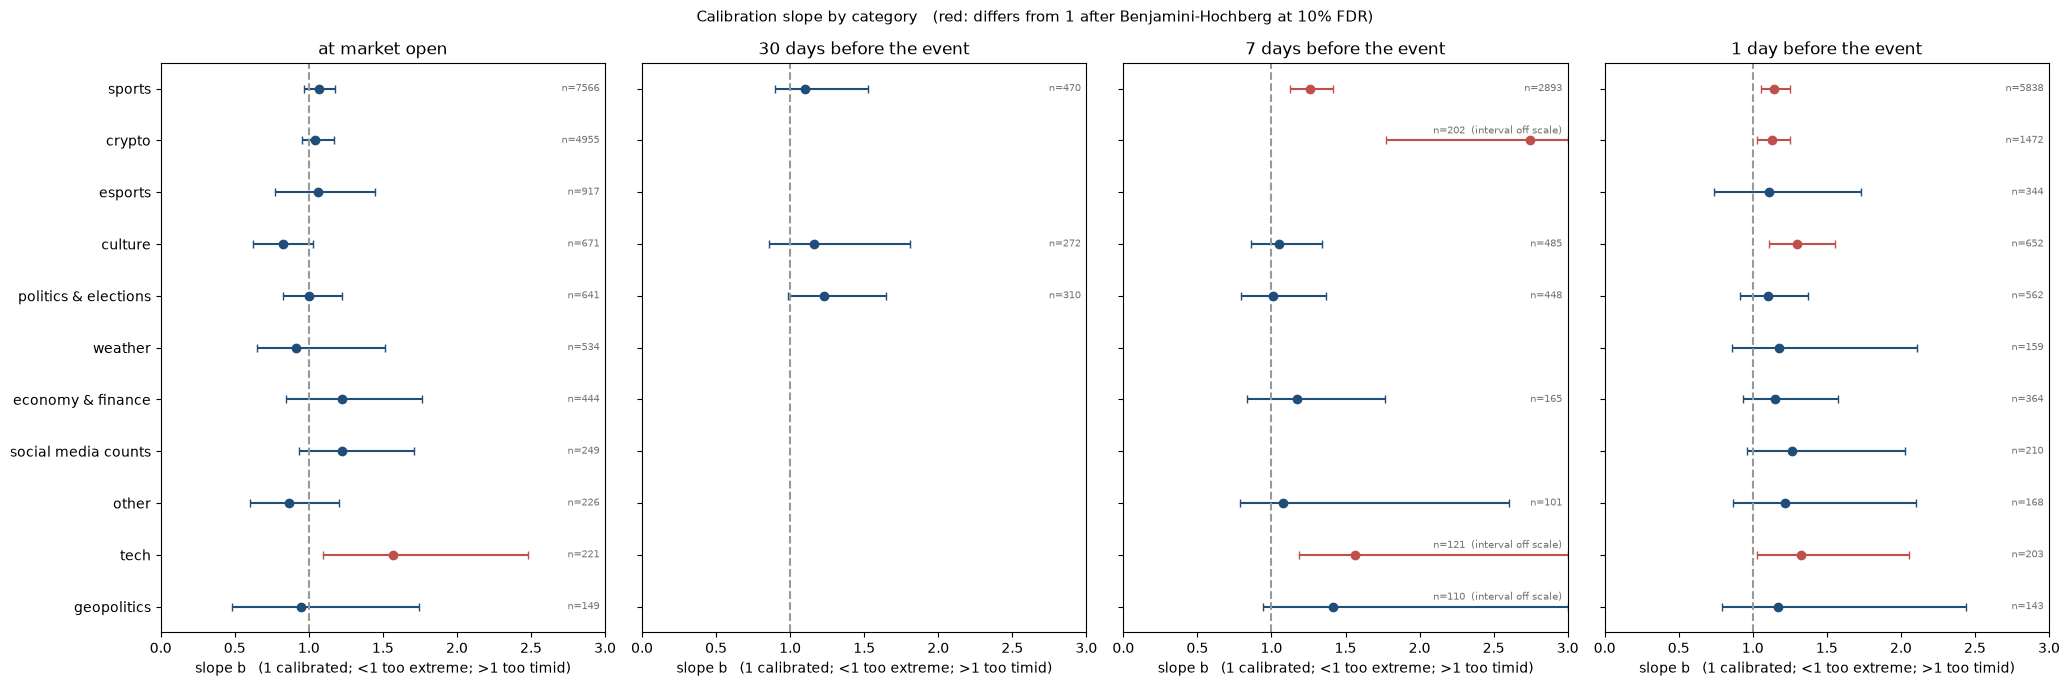

In [12]:
def plot_categories(cats, xmax=3.0):
    order = list(cats[list(cats)[0]].index)                       # fixed row order: by market count at the first horizon
    for t in cats.values(): order += [c for c in t.index if c not in order]
    fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5.2 * len(HORIZONS), 0.45 * len(order) + 2), sharey=True, squeeze=False); axes = axes[0]
    for j, (qc, title) in enumerate(HORIZONS.items()):
        t = cats[qc]; ax = axes[j]
        for i, c in enumerate(order):
            if c not in t.index: continue
            r = t.loc[c]; col = '#c0504d' if r.miscalibrated_after_BH else '#1f4e79'
            lo, hi = max(r.slope_lo, 0), min(r.slope_hi, xmax)
            ax.errorbar(min(r.slope, xmax), i, xerr=[[min(r.slope, xmax) - lo], [hi - min(r.slope, xmax)]], fmt='o', color=col, capsize=3)
            ax.annotate(f'n={int(r.markets)}' + ('  (interval off scale)' if r.slope_hi > xmax else ''), (xmax, i), xytext=(-4, 7 if r.slope_hi > xmax else 0),
                        textcoords='offset points', ha='right', va='center', fontsize=7, color='0.45')
        ax.axvline(1, ls='--', color='0.6'); ax.set(xlim=(0, xmax), title=title, xlabel='slope b   (1 calibrated; <1 too extreme; >1 too timid)')
    axes[0].set_yticks(range(len(order)), order); axes[0].invert_yaxis()
    fig.suptitle('Calibration slope by category   (red: differs from 1 after Benjamini-Hochberg at 10% FDR)', fontsize=11)
    fig.tight_layout(); plt.show()

plot_categories(cats)

At opening, tech is the only category flagged after adjustment, with slope 1.565 [1.096, 2.482]. At 30 days, none of the three eligible categories is flagged. At 7 days, sports, crypto, and tech are flagged; at 1 day, sports, crypto, culture, and tech are flagged. These flags concern slope departures from one, not every possible form of miscalibration.

The category estimates also differ in precision. For example, the 7-day crypto slope is 2.749 [1.773, 36.831], showing substantial uncertainty in its magnitude despite the flag. Market count alone does not determine precision: crypto has 4,955 opening observations but only 239 series, compared with 5,856 series for 7,566 sports observations. The clustered intervals reflect that distinction. A flag in one category and no flag in another is not itself a test that their slopes differ.


### 4.3 Dependence between markets
The within-series residual-pair statistic is computed from $r_i=Y_i-q_i$, pooling products within a series and normalizing by products of $\sqrt{q_i(1-q_i)}$. Its interval uses 400 whole-series bootstrap resamples with fresh IDs for repeated draws. It is a dependence diagnostic relative to the quoted probabilities; systematic calibration error can also contribute to it.

The perfect-calibration reference is then simulated with latent correlations $\rho=0,0.05,0.10,0.20,0.30$. This checks how the ECE and slope comparisons change under positive within-series dependence.

In [13]:
def latent_sensitivity(d, qc, rng, rhos=(0, .05, .1, .2, .3), n_sim=1000):
    q, y = d[qc].to_numpy(), d.y.to_numpy(); bins = bin_index(q); cl = d.series.to_numpy()
    e_obs = ece(q, y, bins); b_obs = calib_fit(q, y)[0][1]; rows = []
    for rho in rhos:
        sims = simulate_outcomes(q, rng, n_sim, cl, rho).astype(float)
        e_null = np.array([ece(q, s, bins) for s in sims])
        b_null = np.array([calib_fit(q, s)[0][1] for s in sims[:300]])
        rows.append(dict(latent_rho=rho, implied_outcome_corr=np.mean([outcome_correlation(q, s, cl) for s in sims[:100]]),
                         ece_null_95=np.quantile(e_null, .95), ece_observed=e_obs, ece_p=(e_null >= e_obs).mean(),
                         slope_null_lo=np.quantile(b_null, .025), slope_null_hi=np.quantile(b_null, .975), slope_observed=b_obs))
    return pd.DataFrame(rows)

for qc, title in HORIZONS.items():
    dh = d.dropna(subset=[qc])
    r = outcome_correlation(dh[qc].to_numpy(), dh.y.to_numpy(), dh.series.to_numpy())
    lo, hi = ci(cluster_boot(dh[[qc, 'y', 'series']], 'series',
                             lambda s: outcome_correlation(s[qc].to_numpy(), s.y.to_numpy(), s['_bc'].to_numpy()), rng, 400))
    print(f'{title}: within-series outcome correlation {r:+.3f}  [{lo:+.3f}, {hi:+.3f}]')
sensitivity = pd.concat({HORIZONS[qc]: latent_sensitivity(d.dropna(subset=[qc]), qc, rng) for qc in HORIZONS}, names=['horizon'])
sensitivity.round(3)

at market open: within-series outcome correlation +0.008  [+0.003, +0.016]


30 days before the event: within-series outcome correlation +0.031  [-0.270, +0.317]


7 days before the event: within-series outcome correlation +0.224  [+0.148, +0.302]


1 day before the event: within-series outcome correlation +0.065  [+0.028, +0.100]


latent_rho  implied_outcome_corr  ece_null_95  ece_observed  ece_p  slope_null_lo  slope_null_hi  slope_observed
horizon                                                                                                                                     
at market open           0        0.00                -0.000        0.011         0.047    0.0          0.943          1.057           1.098
                         1        0.05                 0.031        0.016         0.047    0.0          0.939          1.060           1.098
                         2        0.10                 0.061        0.019         0.047    0.0          0.943          1.062           1.098
                         3        0.20                 0.123        0.025         0.047    0.0          0.926          1.083           1.098
                         4        0.30                 0.190        0.029         0.047    0.0          0.909          1.097           1.098
30 days before the event 0        0.00                 0.004        0.026         0.041    0.0          0.896          1.148           1.111
                         1        0.05                 0.026        0.026         0.041    0.0          0.910          1.132           1.111
                         2        0.10                 0.057        0.026         0.041    0.0          0.897          1.132           1.111
                         3        0.20                 0.094        0.026         0.041    0.0          0.883          1.134           1.111
                         4        0.30                 0.158        0.027         0.041    0.0          0.876          1.149           1.111
7 days before the event  0        0.00                -0.001        0.018         0.047    0.0          0.936          1.088           1.200
                         1        0.05                 0.025        0.019         0.047    0.0          0.936          1.078           1.200
                         2        0.10                 0.052        0.019         0.047    0.0          0.928          1.086           1.200
                         3        0.20                 0.117        0.019         0.047    0.0          0.926          1.077           1.200
                         4        0.30                 0.175        0.019         0.047    0.0          0.918          1.090           1.200
1 day before the event   0        0.00                 0.000        0.013         0.033    0.0          0.946          1.054           1.149
                         1        0.05                 0.026        0.014         0.033    0.0          0.948          1.065           1.149
                         2        0.10                 0.057        0.015         0.033    0.0          0.941          1.057           1.149
                         3        0.20                 0.109        0.017         0.033    0.0          0.942          1.072           1.149
                         4        0.30                 0.174        0.018         0.033    0.0          0.919          1.070           1.149

The residual-pair estimate is 0.008 [0.003, 0.016] at opening, 0.031 [-0.270, 0.317] at 30 days, 0.224 [0.148, 0.302] at 7 days, and 0.065 [0.028, 0.100] at 1 day. Dependence is clearest at 7 days; the 30-day estimate is imprecise.

Observed ECE exceeds the simulated 95th percentile at every tested latent correlation and horizon. For example, at opening the reference percentile rises from about 0.011 to 0.029 as $\rho$ increases, while observed ECE is about 0.047. The opening slope comparison is more sensitive: at $\rho=0.30$, the upper reference bound is about 1.097, very close to the observed 1.098. The ECE conclusion survives this grid more clearly than the opening slope comparison.

This is robustness to the specified positive-factor model. It does not cover all dependence structures, including mutually exclusive outcomes or shocks shared across separate series.


## 5. Verification
The code is checked against known mathematics: perfectly calibrated synthetic data, recovery of a known calibration curve, independent and correlated variance formulas, and an exact Brier identity. The table gives analytic and computed values, absolute differences, and tolerances. The figure compares simulated and analytic standard deviations over a grid of latent correlations.

In [14]:
def verification_checks(rng):
    rows = []
    def add(name, analytic, computed, tol):
        rows.append(dict(check=name, analytic=analytic, computed=computed, abs_diff=abs(computed - analytic), tolerance=tol,
                         agrees=abs(computed - analytic) <= tol))
    # 1-2. limiting case (calibrated data -> a = 0, b = 1) and recovery of a known curve (a = 0.3, b = 0.7),
    #      each averaged over 10 independent replications, so the check tests for bias rather than one draw
    reps = []
    for _ in range(10):
        q = rng.uniform(.02, .98, 100_000)
        y1 = (rng.random(q.size) < q).astype(float); y2 = (rng.random(q.size) < recalibrate(q, [0.3, 0.7])).astype(float)
        (a1, b1), c1 = calib_fit(q, y1); (a2, b2), c2 = calib_fit(q, y2)
        reps.append([a1, b1, a2, b2, *np.sqrt(np.diag(c1)), *np.sqrt(np.diag(c2))])
    m_ = np.mean(reps, axis=0); k = np.sqrt(len(reps))      # SE of a mean of 10 fits = SE / sqrt(10)
    add('calibrated data: slope b = 1 (mean of 10 fits)', 1.0, m_[1], 3 * m_[5] / k)
    add('calibrated data: intercept a = 0 (mean of 10 fits)', 0.0, m_[0], 3 * m_[4] / k)
    add('known curve: slope b = 0.7 (mean of 10 fits)', 0.7, m_[3], 3 * m_[7] / k)
    add('known curve: intercept a = 0.3 (mean of 10 fits)', 0.3, m_[2], 3 * m_[6] / k)
    # 3. Fisher standard error vs bootstrap standard error (independent data, n = 5,000)
    qs, ys = q[:5000], y2[:5000]
    boot = [calib_fit(qs[i], ys[i])[0][1] for i in (rng.integers(0, 5000, 5000) for _ in range(400))]
    fse = np.sqrt(calib_fit(qs, ys)[1][1, 1]); add('Fisher SE of b vs bootstrap SE', fse, np.std(boot), 0.15 * fse)
    # 4. null band at rho = 0: binomial SD of a bin frequency, sqrt(sum q(1-q))/n
    qo = d.q_open.dropna().to_numpy(); qb = qo[bin_index(qo) == 1]
    add('perfect-calibration null: SD of bin frequency', np.sqrt((qb * (1 - qb)).sum()) / qb.size,
        simulate_outcomes(qb, rng, 20_000).mean(1).std(), 0.03 * np.sqrt((qb * (1 - qb)).sum()) / qb.size)
    # 5. correlated null: Var of the mean = p(1-p)/n [1 + (m-1) r],  r from the bivariate normal
    p, m, nc, rho = 0.3, 5, 200, 0.3; t = norm.ppf(p)
    r = (multivariate_normal([0, 0], [[1, rho], [rho, 1]]).cdf([t, t]) - p * p) / (p * (1 - p))
    sd_an = np.sqrt(p * (1 - p) / (m * nc) * (1 + (m - 1) * r))
    sims = simulate_outcomes(np.full(m * nc, p), rng, 20_000, np.repeat(np.arange(nc), m), rho)
    add('correlated null: SD of the mean (design effect)', sd_an, sims.mean(1).std(), 0.03 * sd_an)
    # 6. the residual-correlation estimator recovers the exact outcome correlation r
    est_r = np.mean([outcome_correlation(np.full(m * nc, p), s.astype(float), np.repeat(np.arange(nc), m)) for s in sims[:2000]])
    add('outcome-correlation estimator recovers r', r, est_r, 0.01)
    # 7. correlated null keeps every marginal exactly at q
    qm = rng.uniform(.05, .95, 400); sm = simulate_outcomes(qm, rng, 20_000, rng.integers(0, 40, 400), 0.5)
    add('correlated null: max |P(Y=1) - q| over markets', 0.0, np.abs(sm.mean(0) - qm).max(), 4 * np.sqrt(.25 / 20_000))
    # 8. exact identity: Brier = reliability - resolution + uncertainty when prices are constant within bins
    qd = rng.choice(np.arange(.05, 1, .1), 10_000); yd = (rng.random(qd.size) < qd ** 1.3).astype(float)
    bp = brier_parts(qd, yd, bin_index(qd))
    add('Brier decomposition identity', bp['brier'], bp['reliability'] - bp['resolution'] + bp['uncertainty'], 1e-12)
    return pd.DataFrame(rows).set_index('check')

verification = verification_checks(rng)
print(verification.to_string(formatters={'analytic': '{:.5f}'.format, 'computed': '{:.5f}'.format, 'abs_diff': '{:.1e}'.format, 'tolerance': '{:.1e}'.format}))

                                                   analytic computed abs_diff tolerance  agrees
check                                                                                          
calibrated data: slope b = 1 (mean of 10 fits)      1.00000  1.00020  2.0e-04   6.5e-03    True
calibrated data: intercept a = 0 (mean of 10 fits)  0.00000 -0.00310  3.1e-03   7.2e-03    True
known curve: slope b = 0.7 (mean of 10 fits)        0.70000  0.69878  1.2e-03   5.3e-03    True
known curve: intercept a = 0.3 (mean of 10 fits)    0.30000  0.30007  7.3e-05   6.8e-03    True
Fisher SE of b vs bootstrap SE                      0.02485  0.02597  1.1e-03   3.7e-03    True
perfect-calibration null: SD of bin frequency       0.01212  0.01214  2.3e-05   3.6e-04    True
correlated null: SD of the mean (design effect)     0.01904  0.01897  7.1e-05   5.7e-04    True
outcome-correlation estimator recovers r            0.18163  0.18212  4.9e-04   1.0e-02    True
correlated null: max |P(Y=1) - q| over m

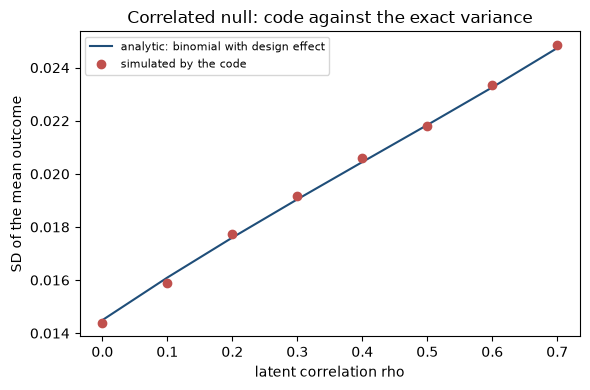

In [15]:
def design_effect_curve(rng, p=0.3, m=5, nc=200, rhos=np.linspace(0, 0.7, 8), n_sim=8000):
    t = norm.ppf(p); cl = np.repeat(np.arange(nc), m); rows = []
    for rho in rhos:
        r = 0.0 if rho == 0 else (multivariate_normal([0, 0], [[1, rho], [rho, 1]]).cdf([t, t]) - p * p) / (p * (1 - p))
        rows.append((rho, np.sqrt(p * (1 - p) / (m * nc) * (1 + (m - 1) * r)),
                     simulate_outcomes(np.full(m * nc, p), rng, n_sim, cl, rho).mean(1).std()))
    return pd.DataFrame(rows, columns=['rho', 'analytic', 'simulated'])

def plot_design_curve(curve):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(curve.rho, curve.analytic, color='#1f4e79', label='analytic: binomial with design effect')
    ax.plot(curve.rho, curve.simulated, 'o', color='#c0504d', label='simulated by the code')
    ax.set(xlabel='latent correlation rho', ylabel='SD of the mean outcome', title='Correlated null: code against the exact variance')
    ax.legend(fontsize=8); fig.tight_layout(); plt.show()

plot_design_curve(design_effect_curve(rng))

All ten reported checks agree within their stated tolerances. Calibrated data recover slope 1.00020 and intercept -0.00310, close to the generating values one and zero. A known curve with $a=0.3,b=0.7$ is recovered as 0.30007 and 0.69878. These check the fitting routine against known parameters rather than against an empirical pattern.

The Fisher slope standard error, 0.02485, agrees with the independent bootstrap estimate, 0.02597, within the chosen tolerance. The independent-bin frequency standard deviation is 0.01214 compared with the analytic 0.01212. For correlated outcomes, the simulated standard deviation is 0.01897 compared with 0.01904 from the exact design-effect formula. The residual-pair estimator recovers correlation 0.18212 against the analytic 0.18163, and the marginal-probability check is within its simulation tolerance.

Finally, the Brier decomposition agrees to the displayed numerical precision for forecasts constant within bins. This checks the exact identity in the case where it applies. These results support the mathematical implementation; validity of the empirical timestamp and outcome measurements is a separate question.


## 6. Validation and a baseline

Fit the calibration curves on markets resolving before January 1, 2026, then score later markets that the curve fitting did not use. Compare logistic and isotonic recalibration with two simple baselines: the raw market probability and the constant outcome rate from the fitting period. All four methods use the same held-out contracts and the same metrics, Brier score and log loss.

The paired score differences carry 95% intervals from 1,000 whole-series bootstrap resamples of the held-out data. Each resample scores the same contracts under every method. The fitted curves are held fixed, so these intervals describe test-sample uncertainty conditional on the fits. The comparison with isotonic recalibration assesses whether a more flexible monotone curve improves held-out prediction.


In [16]:
def validate(d, qc, rng, split=SPLIT_DATE, n_boot=1000):
    fit, test = d[d.t_resolve < split], d[d.t_resolve >= split]
    ab, cov = calib_fit(fit[qc].to_numpy(), fit.y.to_numpy()); base = fit.y.mean()
    iso = IsotonicRegression(out_of_bounds='clip').fit(fit[qc].to_numpy(), fit.y.to_numpy())   # shape-free alternative
    names = ['raw market price (no model)', 'recalibrated, logistic (the model)', 'recalibrated, isotonic (shape-free)', 'base rate (no model)']
    def scores(s):
        q, y = s[qc].to_numpy(), s.y.to_numpy()
        preds = [q, recalibrate(q, ab), iso.predict(q), np.full(len(q), base)]
        return np.r_[[np.mean((p - y) ** 2) for p in preds], [log_loss(p, y) for p in preds]]
    point = scores(test); bs = cluster_boot(test[[qc, 'y', 'series']], 'series', scores, rng, n_boot); lo, hi = ci(bs); k = len(names)
    table = pd.DataFrame({'Brier': point[:k], 'Brier_lo': lo[:k], 'Brier_hi': hi[:k], 'log_loss': point[k:], 'log_loss_lo': lo[k:], 'log_loss_hi': hi[k:]}, index=names)
    diffs = pd.DataFrame({'Brier difference': [point[1] - point[0], point[2] - point[1]],
                          'lo': [ci(bs[:, 1] - bs[:, 0])[0], ci(bs[:, 2] - bs[:, 1])[0]], 'hi': [ci(bs[:, 1] - bs[:, 0])[1], ci(bs[:, 2] - bs[:, 1])[1]]},
                         index=['logistic model minus raw price', 'isotonic minus logistic'])
    info = dict(n_fit=len(fit), n_test=len(test), a=ab[0], b=ab[1], a_se=np.sqrt(cov[0, 0]), b_se=np.sqrt(cov[1, 1]))
    return table, diffs, info, ab, test

validation = {qc: validate(d.dropna(subset=[qc]), qc, rng) for qc in HORIZONS}
for qc, (table, diffs, info, ab, test) in validation.items():
    print(f'\n=== {HORIZONS[qc]}: fitted on {info["n_fit"]} markets resolving before {SPLIT_DATE}: '
          f'a = {info["a"]:.3f} (SE {info["a_se"]:.3f}), b = {info["b"]:.3f} (SE {info["b_se"]:.3f}); scored on {info["n_test"]} held-out markets')
    print(table.round(4).to_string()); print(diffs.round(4).to_string(), '   (negative = first is better)')


=== at market open: fitted on 11626 markets resolving before 2026-01-01: a = -0.211 (SE 0.021), b = 1.092 (SE 0.035); scored on 4944 held-out markets
                                      Brier  Brier_lo  Brier_hi  log_loss  log_loss_lo  log_loss_hi
raw market price (no model)          0.2181    0.2123    0.2233    0.6168       0.6025       0.6298
recalibrated, logistic (the model)   0.2154    0.2091    0.2210    0.6111       0.5959       0.6253
recalibrated, isotonic (shape-free)  0.2139    0.2074    0.2199    0.6081       0.5926       0.6233
base rate (no model)                 0.2415    0.2367    0.2464    0.6761       0.6664       0.6862
                                Brier difference      lo      hi
logistic model minus raw price           -0.0027 -0.0043 -0.0011
isotonic minus logistic                  -0.0015 -0.0024 -0.0006    (negative = first is better)

=== 30 days before the event: fitted on 900 markets resolving before 2026-01-01: a = -0.263 (SE 0.132), b = 1.142 (SE 0.1

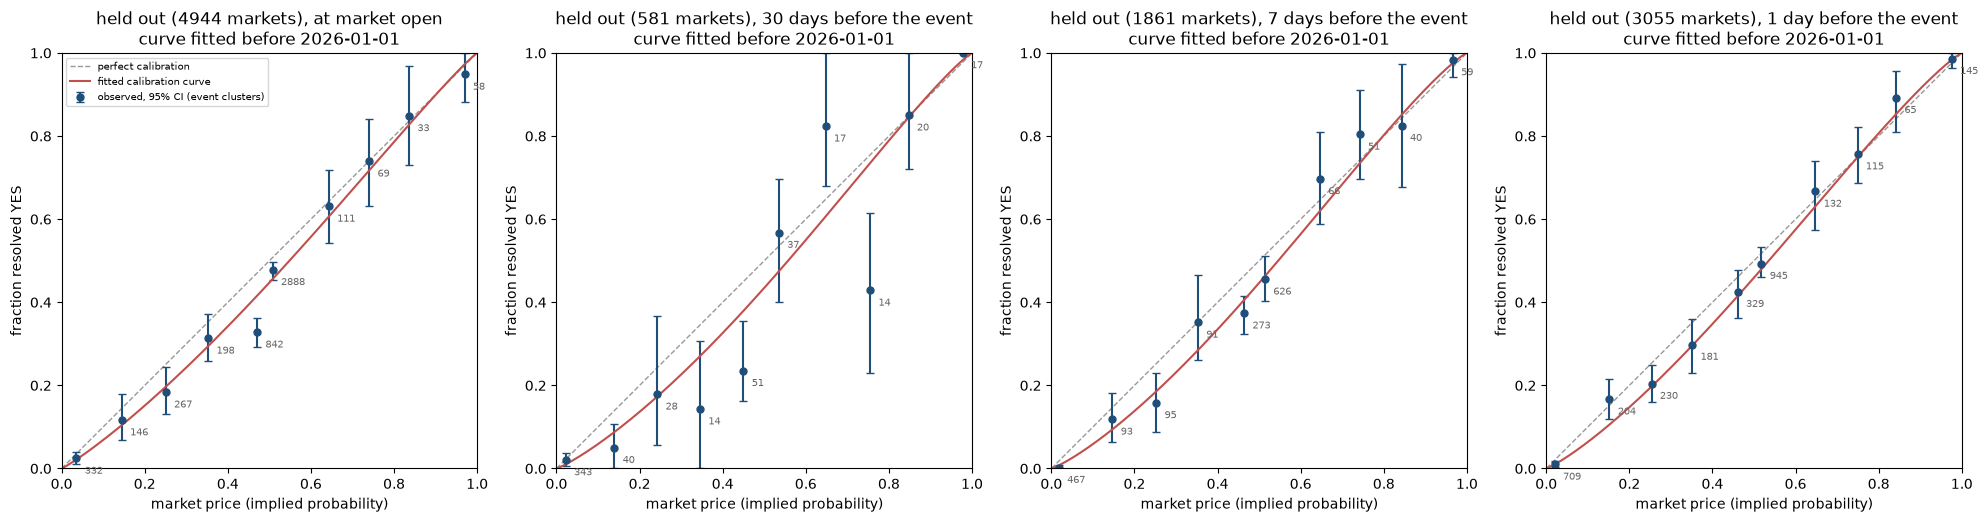

In [17]:
def plot_validation(validation, rng):
    fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5 * len(HORIZONS), 5), squeeze=False); axes = axes[0]
    for j, (qc, title) in enumerate(HORIZONS.items()):
        table, diffs, info, ab, test = validation[qc]
        tab, bins = reliability_table(test[qc].to_numpy(), test.y.to_numpy())
        lohi = [ci(cluster_boot(test[bins == k][[qc, 'y', 'event']], 'event', lambda s: s.y.mean(), rng, 300)) for k in tab.bin]
        tab['lo'], tab['hi'] = [x[0] for x in lohi], [x[1] for x in lohi]
        reliability_plot(axes[j], tab, f'held out ({info["n_test"]} markets), {title}\ncurve fitted before {SPLIT_DATE}',
                         curve=lambda x, ab=ab: recalibrate(x, ab))
    axes[0].legend(fontsize=7, loc='upper left'); fig.tight_layout(); plt.show()

plot_validation(validation, rng)

Logistic recalibration gives small held-out Brier improvements at opening, 30 days, and 7 days. At opening, the raw score is 0.2181 and the corrected score is 0.2154; the paired difference is -0.0027 [-0.0043, -0.0011]. The 30-day difference is -0.0026 [-0.0051, -0.0001], and the 7-day difference is -0.0024 [-0.0046, -0.0001]. All three intervals lie below zero, although the last two are close to zero at their upper bounds. At 1 day, the difference is -0.0004 [-0.0017, 0.0010], so an improvement is uncertain.

The raw and corrected price forecasts have lower point-estimate Brier scores and log losses than the constant base-rate benchmark at every horizon. Market prices therefore provide useful predictive information in these held-out samples, even though the calibration summaries show departures from the perfect-calibration reference.

Isotonic recalibration improves on logistic at opening by -0.0015 [-0.0024, -0.0006] in Brier score. This supports allowing a more flexible shape at opening. At the other horizons, the isotonic-minus-logistic intervals contain zero; those comparisons do not identify a clear winner or establish that the logistic shape is exactly correct.

The result is a modest predictive gain from recalibration in some settings, rather than a large correction that uniformly improves every horizon. These are comparisons within each horizon's retained later-market sample, under the preprocessing and temporal assumptions above.


## 7. What changed after section
**No M2 feedback was returned to our group.** We submitted the Milestone 2 write-up and slides on October 2, 2026, and our section TF did not return comments on them, so there is no feedback to take up or set aside. We held the final analysis to the critique we did have: the lessons and plan we stated in M2 itself, and the critiques our group raised against the M2 model. Each is either taken up or set aside with a reason below.

| M2 lesson, plan, or critique | Taken up or set aside | What changed, and where to check |
|---|---|---|
| Prices were recorded for the No side; convert with $P(\text{Yes}) = 1 - q$. | Taken up as a test, not a fixed flip | `extract_full.py` reads the YES token's price. Orientation is now checked rather than assumed: the AUCs are 0.70 to 0.94 with 95% intervals excluding 0.5, so no flip is applied (*Load the data and check orientation*). |
| "One day before" was counted from settlement, so some prices came after the outcome was known. | Taken up; independent timestamp checks set aside | Horizons now count back from the event anchor, the earlier of market end and resolution, and a price counts only if its last real trade is at most `STALE_MAX_DAYS` = 3 days old. We could not check each timestamp against an independent public-event time, because the data has none; Section 2 reports the share of near-certain prices (12.9%) and Section 8 states the limit. |
| Opening prices are placeholders; drop them and use 30-, 7-, and 1-day prices. | Set aside in part | We report the three later horizons as planned, but keep the opening price as a fourth horizon instead of dropping it: only 36.6% of opening prices are exactly 0.50 (Section 2), so most are not placeholders, and the opening horizon is the only one covering all 16,573 priced markets. |
| Linked markets (20% Elon Musk tweet markets in the pilot) are not independent trials; group them for error bars. | Taken up | Series-bootstrap intervals for every fitted quantity, event-bootstrap intervals on each bin, the within-series outcome correlation, and a correlated perfect-calibration null (Sections 4.1 and 4.3). In the full data the largest single series is 1.5% of markets. |
| M2 Assumption 3: markets with similar prices are independent, comparable trials. | Replaced | Pooling within bins remains for the reliability plots, but the headline model is the two-parameter logistic curve (Section 3), and independence is replaced by the clustered resampling above. |
| The M2 slope (0.72 at open, 0.93 at one day) summarised calibration on its own. | Taken up | The group's critique was that a slope alone does not establish calibration. We now report the intercept, ECE, and Brier decomposition beside the slope, and separate sharpness (price histograms) from resolution (Section 4.1). The M2 pilot slopes are superseded: they came from No-side prices and settlement-anchored horizons, and the full-data opening slope is 1.10 [1.04, 1.17]. |
| Run on the roughly 1.79 million-market dataset. | Taken up, with the reduction stated | 581,760 of those markets are final, resolved, and binary; 16,573 of them have a real price. The coverage by category is reported as a selection check, and Section 8 states what it limits. |
| Test whether political markets are systematically too cautious. | Taken up | Section 4.2: the politics & elections slope at opening is 1.00 [0.83, 1.22] and is not flagged after Benjamini–Hochberg, so these data do not show it. |
| Weight each contract equally. | Kept, with a reason | The question concerns contracts as traded, so each contract keeps equal weight. Equal-event and equal-series weights are listed in Section 8 as the next check. |

Two parts were added beyond the M2 plan: verification against known mathematics (Section 5), and validation on later markets against raw-price and base-rate baselines, including an isotonic alternative (Section 6).

## 8. What this does not show
The data do not establish calibration across all of Polymarket. Only 2.8% of eligible resolved binary contracts have a real price in this processed snapshot, and longer horizons retain fewer markets. Sports and crypto dominate the retained sample. Differences between horizons can therefore reflect different contracts and base rates as well as changes in forecast quality.

The event anchor is the earlier of market end and resolution; it is not an independently observed public-revelation time. Good performance near that anchor can include information already known publicly. Outcomes for 99.1% of markets in the loader's initial input are inferred from terminal prices, so the labels concern inferred contract settlement rather than an independent measurement of the headline event. The retained output also includes resolution timestamps after the stated snapshot date; administrative dates need care in interpreting a resolution-date split.

The two-parameter curve can miss nonlinear and subgroup patterns, as the opening isotonic comparison suggests. The cluster bootstrap relies on the chosen event and series definitions. The positive-factor simulation does not enforce mutual exclusivity or capture dependence across series. Category labels and finite-bootstrap tail measures also limit the precision of exploratory comparisons.

The validation evaluates transfer between resolution-date periods. Its uncertainty intervals hold the fitted curves fixed. Price orientation is checked using labels across the dataset, so the complete preprocessing pipeline is not isolated from the held-out outcomes even though fitting the correction uses earlier markets. A strict prospective test would also require all fitting outcomes to be available before each test forecast cutoff.

Calibration and score improvements do not establish profitable trading or insider information. Trading costs, spreads, liquidity, attainable positions, and execution are outside the model.

Another month would let us audit a stratified sample of token mappings, outcome labels, and actual observation times; compare administrative anchors with independently documented public-event times; and repeat horizon comparisons on matched contracts. We would also test equal-event or equal-series weights, alternative freshness and clipping thresholds, and rolling validation with fitting outcomes available before test forecasts. These checks would help separate persistent calibration behavior from data selection and timing effects.


## 9. Contribution statement
**Jacob Lin:** data pipeline and exploration: `extract_full.py` (streaming the raw snapshot into `full_markets.parquet`), `find_data`, `load_markets`, the category rules `CATS`, `COARSE`, `categorise`, `coarse_category` and `template`, the coverage, composition and orientation checks in *Load the data and check orientation*, and the plotting functions `reliability_plot`, `plot_horizons` and `plot_categories`. Wrote Sections 1-2.

**Mustapha Sadiq:** model and statistics: `calib_fit`, `recalibrate`, `reliability_table`, `ece`, `brier_parts`, `log_loss`, `cluster_boot`, `ci`, `simulate_outcomes`, `outcome_correlation`, and the analyses built on them, `fit_horizon`, `binning_robustness`, `by_category` (with the Benjamini-Hochberg step) and `latent_sensitivity`. Wrote Sections 3-4.

**Hanser Yoon:** verification and validation: `verification_checks`, `design_effect_curve`, `plot_design_curve`, `validate` (temporal split, isotonic alternative, raw-price and base-rate baselines, paired bootstrap differences) and `plot_validation`. Wrote Sections 5-8.